In [1]:
# ==========================================
# PART 1: IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import copy
import time

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms

from torch.utils.data import (
    DataLoader,
    TensorDataset
)


# ==========================================
# RANDOM SEED
# ==========================================

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

random.seed(RANDOM_SEED)

torch.manual_seed(RANDOM_SEED)


# GPU seed if available
if torch.cuda.is_available():

    torch.cuda.manual_seed(RANDOM_SEED)

    torch.cuda.manual_seed_all(RANDOM_SEED)


# ==========================================
# SELECT DEVICE
# ==========================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: cuda


In [2]:
# ==========================================
# PART 3: LOAD DATA
# ==========================================

train_df = pd.read_csv('/content/fashion-mnist_train.csv.zip')

test_df = pd.read_csv('/content/fashion-mnist_test.csv.zip')


print("Training Data Shape:")

print(train_df.shape)


print("\nTesting Data Shape:")

print(test_df.shape)

Training Data Shape:
(60000, 785)

Testing Data Shape:
(10000, 785)


In [3]:
# ==========================================
# PART 4: INSPECT DATA
# ==========================================

print("Training Dataset:")

display(
    train_df.head()
)


print("\nTesting Dataset:")

display(
    test_df.head()
)


print("\nColumns:")

print(
    train_df.columns
)

Training Dataset:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Testing Dataset:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Columns:
Index(['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6',
       'pixel7', 'pixel8', 'pixel9',
       ...
       'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779', 'pixel780',
       'pixel781', 'pixel782', 'pixel783', 'pixel784'],
      dtype='object', length=785)


In [4]:
fashion_classes = {

    0: "T-shirt/top",

    1: "Trouser",

    2: "Pullover",

    3: "Dress",

    4: "Coat",

    5: "Sandal",

    6: "Shirt",

    7: "Sneaker",

    8: "Bag",

    9: "Ankle boot"

}

In [5]:
# ==========================================
# PART 5: SELECT 5 CLASSES
# ==========================================

selected_classes = [

    0,

    1,

    2,

    3,

    4

]


print("Selected Classes:")


for class_id in selected_classes:

    print(
        class_id,
        ":",
        fashion_classes[class_id]
    )

Selected Classes:
0 : T-shirt/top
1 : Trouser
2 : Pullover
3 : Dress
4 : Coat


In [6]:
# ==========================================
# PART 6: FILTER SELECTED CLASSES
# ==========================================

train_df_selected = train_df[
    train_df["label"].isin(
        selected_classes
    )
].copy()


test_df_selected = test_df[
    test_df["label"].isin(
        selected_classes
    )
].copy()


print(
    "Selected Training Data Shape:",
    train_df_selected.shape
)


print(
    "Selected Test Data Shape:",
    test_df_selected.shape
)

Selected Training Data Shape: (30000, 785)
Selected Test Data Shape: (5000, 785)


In [8]:
# ==========================================
# PART 7: REMAP LABELS
# ==========================================

label_mapping = {

    old_label: new_label

    for new_label, old_label

    in enumerate(selected_classes)

}


print("Label Mapping:")

print(
    label_mapping
)

Label Mapping:
{0: 0, 1: 1, 2: 2, 3: 3, 4: 4}


In [9]:
# ==========================================
# PART 8: FEATURES AND LABELS
# ==========================================

X_train_original = (
    train_df_selected
    .drop(
        columns=["label"]
    )
    .values
)


y_train_original = (
    train_df_selected["label"]
    .values
)


X_test_original = (
    test_df_selected
    .drop(
        columns=["label"]
    )
    .values
)


y_test_original = (
    test_df_selected["label"]
    .values
)


print(
    "Training Features:",
    X_train_original.shape
)


print(
    "Training Labels:",
    y_train_original.shape
)


print(
    "Test Features:",
    X_test_original.shape
)


print(
    "Test Labels:",
    y_test_original.shape
)

Training Features: (30000, 784)
Training Labels: (30000,)
Test Features: (5000, 784)
Test Labels: (5000,)


In [10]:
# ==========================================
# PART 9: NORMALIZE DATA
# ==========================================

X_train_original = (
    X_train_original.astype(
        np.float32
    )
    / 255.0
)


X_test_original = (
    X_test_original.astype(
        np.float32
    )
    / 255.0
)


print(
    "Pixel Range:"
)


print(
    "Minimum:",
    X_train_original.min()
)


print(
    "Maximum:",
    X_train_original.max()
)

Pixel Range:
Minimum: 0.0
Maximum: 1.0


In [11]:
# ==========================================
# PART 10: STRATIFIED TRAIN-VALIDATION SPLIT
# ==========================================

def stratified_train_validation_split(
    X,
    y,
    validation_ratio=0.20,
    random_seed=42
):

    np.random.seed(
        random_seed
    )


    X_train_list = []

    X_val_list = []

    y_train_list = []

    y_val_list = []


    # Process every class separately

    for class_label in np.unique(y):


        # Get indices for current class

        class_indices = np.where(
            y == class_label
        )[0]


        # Shuffle indices

        np.random.shuffle(
            class_indices
        )


        # Number of validation samples

        n_validation = int(
            len(class_indices)
            * validation_ratio
        )


        # Validation indices

        validation_indices = (
            class_indices[
                :n_validation
            ]
        )


        # Training indices

        training_indices = (
            class_indices[
                n_validation:
            ]
        )


        # Store training data

        X_train_list.append(
            X[
                training_indices
            ]
        )


        y_train_list.append(
            y[
                training_indices
            ]
        )


        # Store validation data

        X_val_list.append(
            X[
                validation_indices
            ]
        )


        y_val_list.append(
            y[
                validation_indices
            ]
        )


    # Combine all classes

    X_train = np.vstack(
        X_train_list
    )


    X_val = np.vstack(
        X_val_list
    )


    y_train = np.concatenate(
        y_train_list
    )


    y_val = np.concatenate(
        y_val_list
    )


    return (

        X_train,

        X_val,

        y_train,

        y_val

    )

In [12]:
# ==========================================
# PART 11: CREATE TRAIN AND VALIDATION DATA
# ==========================================

(

    X_train,

    X_val,

    y_train,

    y_val

) = stratified_train_validation_split(

    X_train_original,

    y_train_original,

    validation_ratio=0.20,

    random_seed=RANDOM_SEED

)


# The provided Fashion-MNIST test dataset
# will be our final test data

X_test = X_test_original

y_test = y_test_original


print(
    "Training Data:",
    X_train.shape
)


print(
    "Validation Data:",
    X_val.shape
)


print(
    "Testing Data:",
    X_test.shape
)

Training Data: (24000, 784)
Validation Data: (6000, 784)
Testing Data: (5000, 784)


In [13]:
# ==========================================
# PART 12: VERIFY CLASS DISTRIBUTION
# ==========================================

print("TRAINING DATA")


for class_id in range(5):

    count = np.sum(
        y_train == class_id
    )

    print(
        f"Class {class_id}:",
        count
    )


print("\nVALIDATION DATA")


for class_id in range(5):

    count = np.sum(
        y_val == class_id
    )

    print(
        f"Class {class_id}:",
        count
    )


print("\nTEST DATA")


for class_id in range(5):

    count = np.sum(
        y_test == class_id
    )

    print(
        f"Class {class_id}:",
        count
    )

TRAINING DATA
Class 0: 4800
Class 1: 4800
Class 2: 4800
Class 3: 4800
Class 4: 4800

VALIDATION DATA
Class 0: 1200
Class 1: 1200
Class 2: 1200
Class 3: 1200
Class 4: 1200

TEST DATA
Class 0: 1000
Class 1: 1000
Class 2: 1000
Class 3: 1000
Class 4: 1000


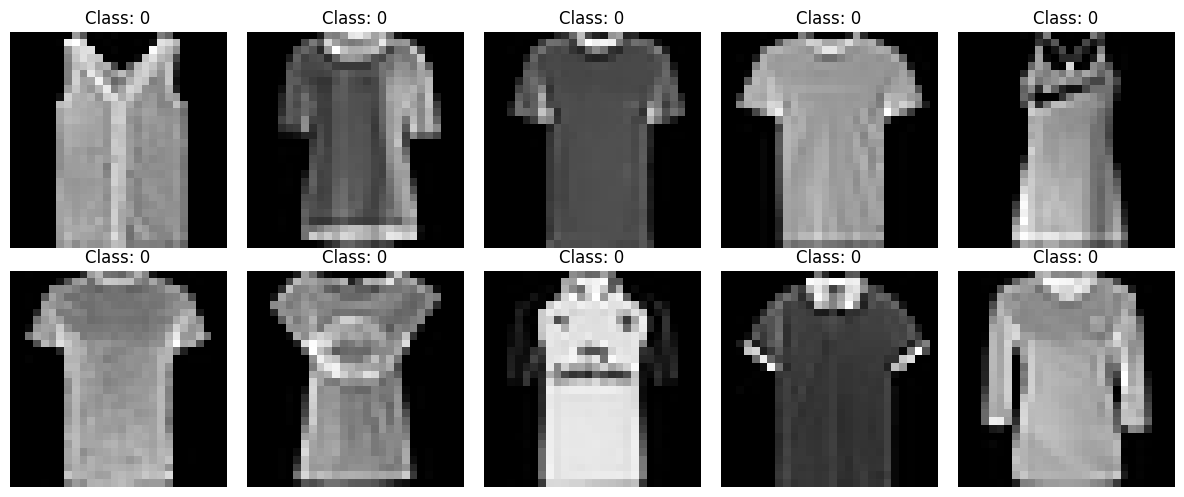

In [14]:
# ==========================================
# PART 13: DISPLAY SAMPLE IMAGES
# ==========================================

plt.figure(
    figsize=(12, 5)
)


for i in range(10):


    plt.subplot(
        2,
        5,
        i + 1
    )


    image = X_train[i].reshape(
        28,
        28
    )


    plt.imshow(
        image,
        cmap="gray"
    )


    plt.title(
        f"Class: {y_train[i]}"
    )


    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()

In [15]:
# ==========================================
# PART 14: CONVERT DATA TO TENSORS
# ==========================================

X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)


y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)


X_val_tensor = torch.tensor(
    X_val,
    dtype=torch.float32
)


y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long
)


X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)


y_test_tensor = torch.tensor(
    y_test,
    dtype=torch.long
)

In [16]:
# ==========================================
# PART 15: CREATE DATASETS
# ==========================================

train_dataset = TensorDataset(

    X_train_tensor,

    y_train_tensor

)


val_dataset = TensorDataset(

    X_val_tensor,

    y_val_tensor

)


test_dataset = TensorDataset(

    X_test_tensor,

    y_test_tensor

)

In [17]:
# ==========================================
# PART 16: DEFINE FCNN ARCHITECTURES
# ==========================================

architectures = {

    # Architecture 1: 3 hidden layers
    "Architecture_1": [
        128,
        64,
        32
    ],

    # Architecture 2: 4 hidden layers
    "Architecture_2": [
        256,
        128,
        64,
        32
    ],

    # Architecture 3: 5 hidden layers
    "Architecture_3": [
        256,
        128,
        64,
        32,
        16
    ]

}

In [18]:
# ==========================================
# PART 17: FCNN MODEL
# ==========================================

class FCNN(nn.Module):


    def __init__(
        self,
        hidden_layers
    ):


        super(
            FCNN,
            self
        ).__init__()


        layers = []


        input_size = 784


        # Create hidden layers

        for hidden_size in hidden_layers:


            layers.append(

                nn.Linear(

                    input_size,

                    hidden_size

                )

            )


            layers.append(

                nn.ReLU()

            )


            input_size = hidden_size


        # Output layer

        layers.append(

            nn.Linear(

                input_size,

                5

            )

        )


        self.network = nn.Sequential(
            *layers
        )


    def forward(
        self,
        x
    ):

        return self.network(
            x
        )

In [19]:
# ==========================================
# PART 18: LOSS FUNCTION
# ==========================================

criterion = nn.CrossEntropyLoss()

print(
    "Cross-Entropy Loss selected!"
)

Cross-Entropy Loss selected!


In [20]:
# ==========================================
# PART 19: PARAMETERS
# ==========================================

learning_rate = 0.001


# Convergence threshold

convergence_threshold = 1e-4


# Momentum

momentum_value = 0.9


# RMSProp

rmsprop_beta = 0.99

rmsprop_epsilon = 1e-8


# Adam

adam_beta1 = 0.9

adam_beta2 = 0.999

adam_epsilon = 1e-8

In [21]:
# ==========================================
# PART 20: OPTIMIZER FUNCTION
# ==========================================

def get_optimizer(
    model,
    optimizer_name,
    train_size
):


    if optimizer_name == "SGD":


        return optim.SGD(

            model.parameters(),

            lr=learning_rate

        )


    elif optimizer_name == "Batch GD":


        return optim.SGD(

            model.parameters(),

            lr=learning_rate

        )


    elif optimizer_name == "Momentum":


        return optim.SGD(

            model.parameters(),

            lr=learning_rate,

            momentum=momentum_value

        )


    elif optimizer_name == "NAG":


        return optim.SGD(

            model.parameters(),

            lr=learning_rate,

            momentum=momentum_value,

            nesterov=True

        )


    elif optimizer_name == "RMSProp":


        return optim.RMSprop(

            model.parameters(),

            lr=learning_rate,

            alpha=rmsprop_beta,

            eps=rmsprop_epsilon

        )


    elif optimizer_name == "Adam":


        return optim.Adam(

            model.parameters(),

            lr=learning_rate,

            betas=(

                adam_beta1,

                adam_beta2

            ),

            eps=adam_epsilon

        )

In [22]:
# ==========================================
# PART 21: ACCURACY FUNCTION
# ==========================================

def calculate_accuracy(
    model,
    X,
    y
):


    model.eval()


    with torch.no_grad():


        X = X.to(
            device
        )


        y = y.to(
            device
        )


        outputs = model(
            X
        )


        predictions = torch.argmax(

            outputs,

            dim=1

        )


        correct = torch.sum(

            predictions == y

        ).item()


        total = len(
            y
        )


        accuracy = (

            correct
            /
            total

        )


    return accuracy

In [23]:
# ==========================================
# PART 22: TRAINING FUNCTION
# ==========================================

def train_model(


    model,

    optimizer,

    train_loader,


    convergence_threshold=1e-4


):


    model.train()


    average_error_history = []


    previous_average_error = None


    epoch = 0


    while True:


        epoch += 1


        total_error = 0


        total_samples = 0


        # Train on batches

        for X_batch, y_batch in train_loader:


            X_batch = X_batch.to(
                device
            )


            y_batch = y_batch.to(
                device
            )


            # Reset gradients

            optimizer.zero_grad()


            # Forward propagation

            outputs = model(
                X_batch
            )


            # Calculate loss

            loss = criterion(

                outputs,

                y_batch

            )


            # Backpropagation

            loss.backward()


            # Update weights

            optimizer.step()


            # Store total error

            total_error += (

                loss.item()
                *
                len(X_batch)

            )


            total_samples += len(
                X_batch
            )


        # Average error

        average_error = (

            total_error
            /
            total_samples

        )


        average_error_history.append(
            average_error
        )


        # Check convergence

        if previous_average_error is not None:


            difference = abs(

                average_error

                -

                previous_average_error

            )


            if (

                difference
                <
                convergence_threshold

            ):


                print(

                    "Converged!"

                )


                break


        previous_average_error = (
            average_error
        )


    return (

        model,

        average_error_history,

        epoch

    )

In [24]:
# ==========================================
# PART 23: OPTIMIZERS
# ==========================================

optimizer_names = [

    "SGD",

    "Batch GD",

    "Momentum",

    "NAG",

    "RMSProp",

    "Adam"

]

In [25]:
# ==========================================
# PART 24: TRAIN ALL MODELS
# ==========================================

all_results = []


trained_models = {}


for architecture_name, hidden_layers in architectures.items():


    print(

        "\n"

        + "=" * 60

    )


    print(

        "Architecture:",

        architecture_name

    )


    print(

        "Hidden Layers:",

        hidden_layers

    )


    print(

        "=" * 60

    )


    trained_models[
        architecture_name
    ] = {}


    for optimizer_name in optimizer_names:


        print(

            "\nTraining with:",

            optimizer_name

        )


        # ----------------------------------
        # SAME INITIAL WEIGHTS
        # ----------------------------------

        torch.manual_seed(
            RANDOM_SEED
        )


        # Create model

        model = FCNN(

            hidden_layers

        ).to(
            device
        )


        # ----------------------------------
        # CREATE DATALOADER
        # ----------------------------------

        if optimizer_name == "Batch GD":


            batch_size = len(
                train_dataset
            )


        else:


            batch_size = 100


        train_loader = DataLoader(

            train_dataset,

            batch_size=batch_size,

            shuffle=True

        )


        # ----------------------------------
        # CREATE OPTIMIZER
        # ----------------------------------

        optimizer = get_optimizer(

            model,

            optimizer_name,

            len(train_dataset)

        )


        # ----------------------------------
        # TRAIN MODEL
        # ----------------------------------

        start_time = time.time()


        (

            trained_model,

            error_history,

            epochs

        ) = train_model(

            model,

            optimizer,

            train_loader,

            convergence_threshold

        )


        end_time = time.time()


        execution_time = (

            end_time

            -

            start_time

        )


        # ----------------------------------
        # CALCULATE ACCURACY
        # ----------------------------------

        training_accuracy = (

            calculate_accuracy(

                trained_model,

                X_train_tensor,

                y_train_tensor

            )

        )


        validation_accuracy = (

            calculate_accuracy(

                trained_model,

                X_val_tensor,

                y_val_tensor

            )

        )


        # ----------------------------------
        # STORE MODEL
        # ----------------------------------

        trained_models[
            architecture_name
        ][
            optimizer_name
        ] = trained_model


        # ----------------------------------
        # STORE RESULTS
        # ----------------------------------

        all_results.append({


            "Architecture":

                architecture_name,


            "Hidden Layers":

                hidden_layers,


            "Optimizer":

                optimizer_name,


            "Epochs to Convergence":

                epochs,


            "Training Accuracy":

                training_accuracy,


            "Validation Accuracy":

                validation_accuracy,


            "Execution Time":

                execution_time,


            "Error History":

                error_history

        })


        print(

            "Epochs:",

            epochs

        )


        print(

            "Training Accuracy:",

            training_accuracy

        )


        print(

            "Validation Accuracy:",

            validation_accuracy

        )


Architecture: Architecture_1
Hidden Layers: [128, 64, 32]

Training with: SGD
Converged!
Epochs: 205
Training Accuracy: 0.888125
Validation Accuracy: 0.8811666666666667

Training with: Batch GD
Converged!
Epochs: 2
Training Accuracy: 0.20991666666666667
Validation Accuracy: 0.20783333333333334

Training with: Momentum
Converged!
Epochs: 59
Training Accuracy: 0.9084583333333334
Validation Accuracy: 0.8936666666666667

Training with: NAG
Converged!
Epochs: 161
Training Accuracy: 0.966375
Validation Accuracy: 0.9098333333333334

Training with: RMSProp
Converged!
Epochs: 49
Training Accuracy: 0.9720416666666667
Validation Accuracy: 0.9151666666666667

Training with: Adam
Converged!
Epochs: 161
Training Accuracy: 0.997375
Validation Accuracy: 0.9145

Architecture: Architecture_2
Hidden Layers: [256, 128, 64, 32]

Training with: SGD
Converged!
Epochs: 203
Training Accuracy: 0.87875
Validation Accuracy: 0.8706666666666667

Training with: Batch GD
Converged!
Epochs: 2
Training Accuracy: 0.196

In [26]:
# ==========================================
# PART 25: RESULTS TABLE
# ==========================================

results_df = pd.DataFrame(
    all_results
)


# Convert accuracy to percentage

results_df[
    "Training Accuracy"
] = (

    results_df[
        "Training Accuracy"
    ]
    * 100

)


results_df[
    "Validation Accuracy"
] = (

    results_df[
        "Validation Accuracy"
    ]
    * 100

)


display(
    results_df[
        [

            "Architecture",

            "Optimizer",

            "Epochs to Convergence",

            "Training Accuracy",

            "Validation Accuracy",

            "Execution Time"

        ]
    ]
)

,Architecture,Optimizer,Epochs to Convergence,Training Accuracy,Validation Accuracy,Execution Time
0,Architecture_1,SGD,205,88.812500,88.116667,120.202919
1,Architecture_1,Batch GD,2,20.991667,20.783333,0.701394
2,Architecture_1,Momentum,59,90.845833,89.366667,35.521099
3,Architecture_1,NAG,161,96.637500,90.983333,99.220167
4,Architecture_1,RMSProp,49,97.204167,91.516667,31.942188
5,Architecture_1,Adam,161,99.737500,91.450000,107.158693
6,Architecture_2,SGD,203,87.875000,87.066667,127.618024
7,Architecture_2,Batch GD,2,19.650000,19.550000,0.495907
8,Architecture_2,Momentum,74,92.583333,89.450000,48.100391
9,Architecture_2,NAG,68,93.883333,90.866667,44.095630


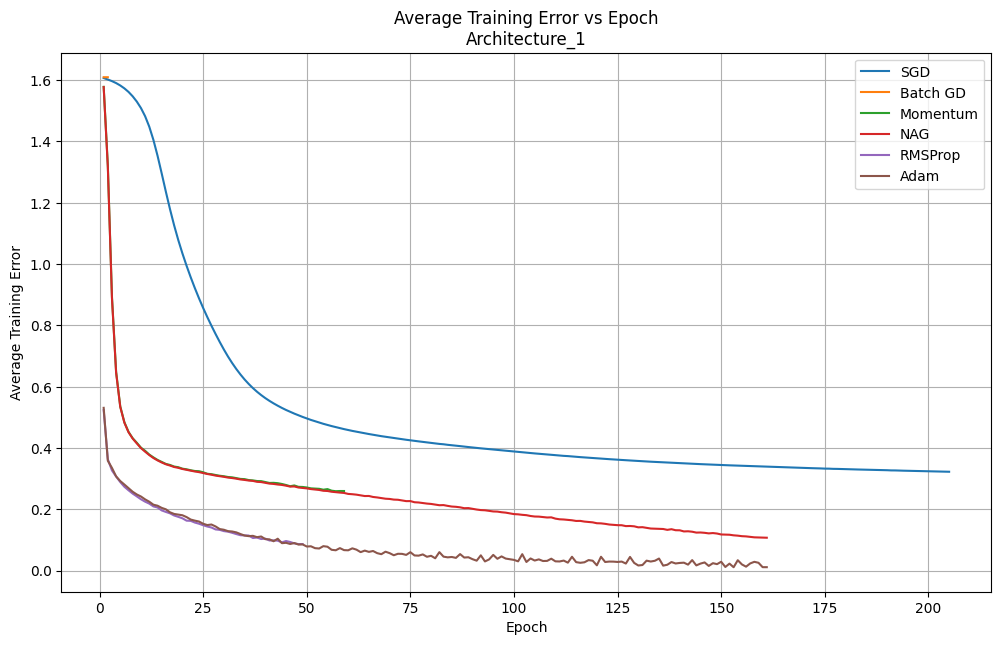

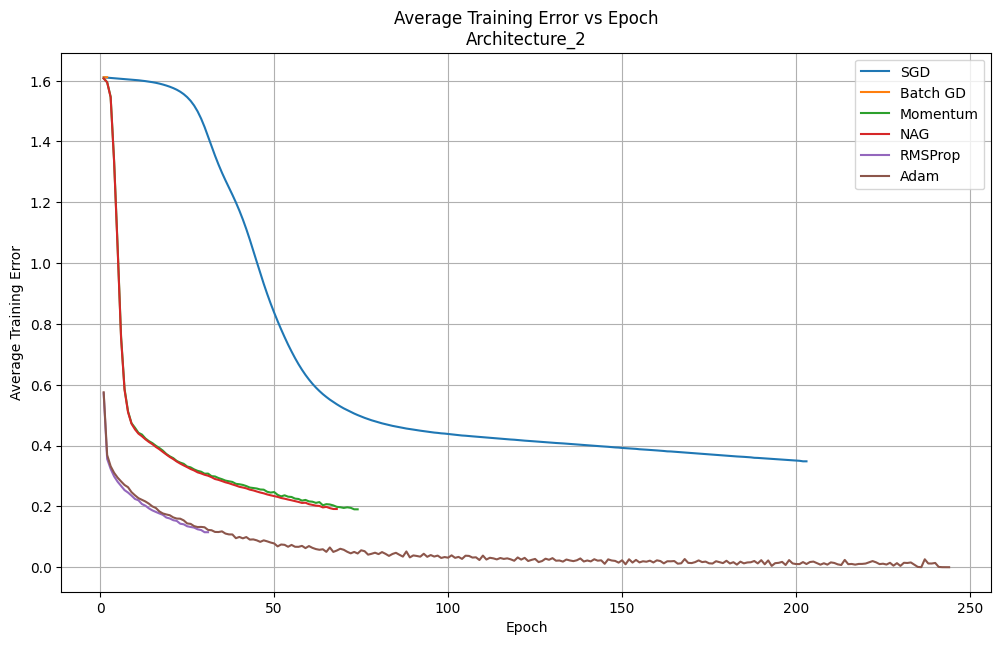

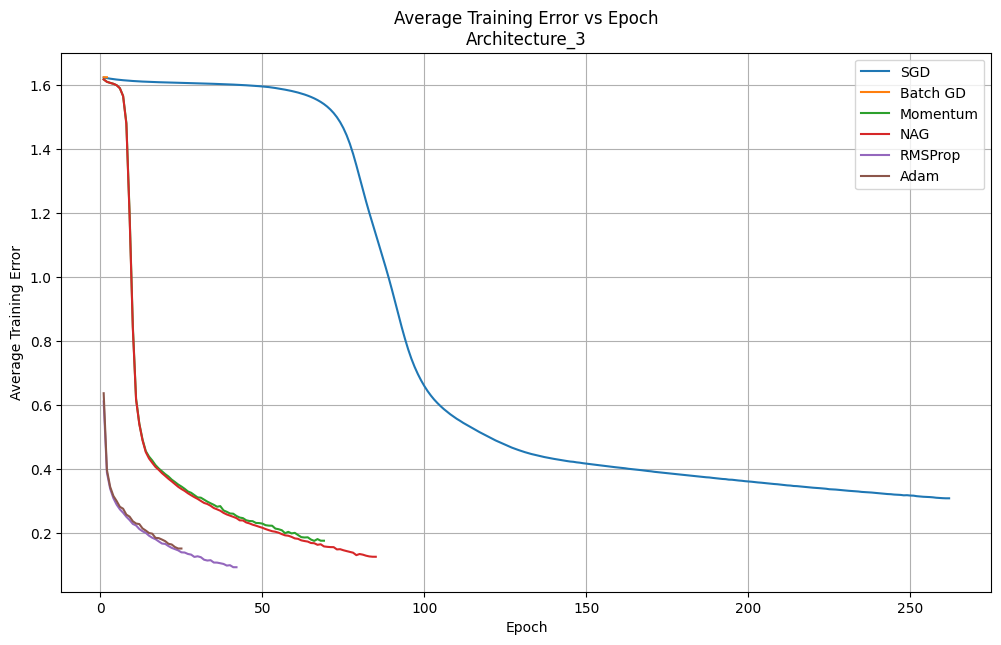

In [27]:
# ==========================================
# PART 26: ERROR VS EPOCH PLOTS
# ==========================================

for architecture_name in architectures.keys():


    plt.figure(

        figsize=(12, 7)

    )


    architecture_results = results_df[

        results_df[
            "Architecture"
        ]
        ==
        architecture_name

    ]


    for _, row in architecture_results.iterrows():


        error_history = row[
            "Error History"
        ]


        optimizer_name = row[
            "Optimizer"
        ]


        plt.plot(

            range(

                1,

                len(
                    error_history
                )
                + 1

            ),

            error_history,

            label=optimizer_name

        )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "Average Training Error"
    )


    plt.title(

        f"Average Training Error vs Epoch\n"
        f"{architecture_name}"

    )


    plt.legend()


    plt.grid()


    plt.show()

In [28]:
# ==========================================
# PART 27: FIND BEST ARCHITECTURE
# ==========================================

best_validation_per_architecture = (

    results_df

    .sort_values(

        "Validation Accuracy",

        ascending=False

    )

    .groupby(

        "Architecture"

    )

    .first()

    .reset_index()

)


display(

    best_validation_per_architecture[

        [

            "Architecture",

            "Optimizer",

            "Validation Accuracy"

        ]

    ]

)

# Find overall best result

best_result = (

    results_df.loc[

        results_df[
            "Validation Accuracy"
        ].idxmax()

    ]

)


print(
    "BEST MODEL RESULT"
)


print(
    best_result[
        [

            "Architecture",

            "Optimizer",

            "Validation Accuracy"

        ]

    ]
)

,Architecture,Optimizer,Validation Accuracy
0,Architecture_1,RMSProp,91.516667
1,Architecture_2,Adam,92.050000
2,Architecture_3,RMSProp,91.283333


BEST MODEL RESULT
Architecture           Architecture_2
Optimizer                        Adam
Validation Accuracy             92.05
Name: 11, dtype: object


In [29]:
# ==========================================
# PART 28: BEST MODEL
# ==========================================

best_architecture = (

    best_result[
        "Architecture"
    ]

)


best_optimizer = (

    best_result[
        "Optimizer"
    ]

)


best_model = (

    trained_models[

        best_architecture

    ][

        best_optimizer

    ]

)


print(
    "Best Architecture:",
    best_architecture
)


print(
    "Best Optimizer:",
    best_optimizer
)

Best Architecture: Architecture_2
Best Optimizer: Adam


In [30]:
# ==========================================
# PART 29: TEST ACCURACY
# ==========================================

test_accuracy = (

    calculate_accuracy(

        best_model,

        X_test_tensor,

        y_test_tensor

    )

)


print(

    f"Test Accuracy: "

    f"{test_accuracy * 100:.2f}%"

)

Test Accuracy: 92.36%


In [31]:
# ==========================================
# PART 30: GET PREDICTIONS
# ==========================================

def get_predictions(
    model,
    X
):


    model.eval()


    with torch.no_grad():


        X = X.to(
            device
        )


        outputs = model(
            X
        )


        predictions = torch.argmax(

            outputs,

            dim=1

        )


    return predictions.cpu().numpy()

In [34]:
# ==========================================
# PART 31: TEST CONFUSION MATRIX
# ==========================================
from sklearn.metrics import accuracy_score, confusion_matrix
y_test_predictions = (

    get_predictions(

        best_model,

        X_test_tensor

    )

)


test_cm = confusion_matrix(

    y_test,

    y_test_predictions

)


print(

    "Test Confusion Matrix:"

)


print(
    test_cm
)

Test Confusion Matrix:
[[946   2  25  24   3]
 [  4 982   4   9   1]
 [ 24   1 863  21  91]
 [ 23   9  12 924  32]
 [  2   0  77  18 903]]


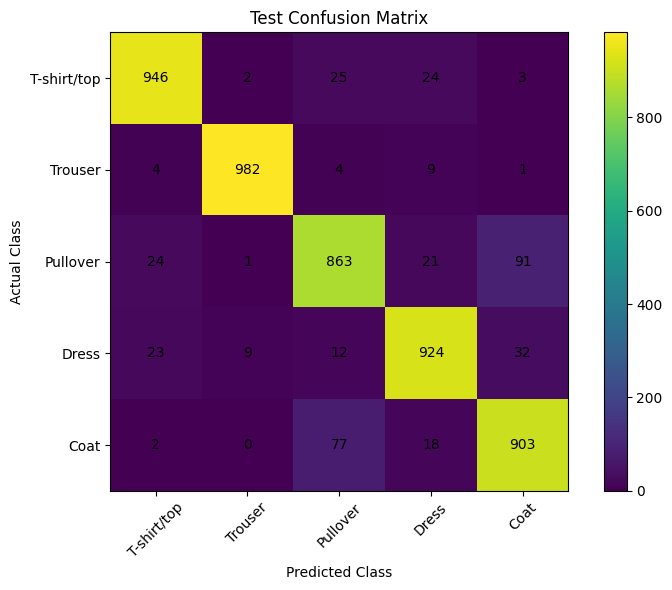

In [35]:
# ==========================================
# PART 32: PLOT CONFUSION MATRIX
# ==========================================

plt.figure(

    figsize=(8, 6)

)


plt.imshow(
    test_cm
)


plt.colorbar()


plt.xlabel(
    "Predicted Class"
)


plt.ylabel(
    "Actual Class"
)


plt.title(
    "Test Confusion Matrix"
)


class_names = [

    fashion_classes[
        original_class
    ]

    for original_class

    in selected_classes

]


plt.xticks(

    range(5),

    class_names,

    rotation=45

)


plt.yticks(

    range(5),

    class_names

)


for i in range(5):


    for j in range(5):


        plt.text(

            j,

            i,

            test_cm[i, j],

            ha="center",

            va="center"

        )


plt.tight_layout()


plt.show()

In [36]:
# ==========================================
# PART 33: TRAINING CONFUSION MATRIX
# ==========================================

y_train_predictions = (

    get_predictions(

        best_model,

        X_train_tensor

    )

)


training_cm = confusion_matrix(

    y_train,

    y_train_predictions

)


print(

    "Training Confusion Matrix:"

)


print(
    training_cm
)

Training Confusion Matrix:
[[4800    0    0    0    0]
 [   0 4800    0    0    0]
 [   0    0 4800    0    0]
 [   0    0    0 4800    0]
 [   0    0    0    0 4800]]


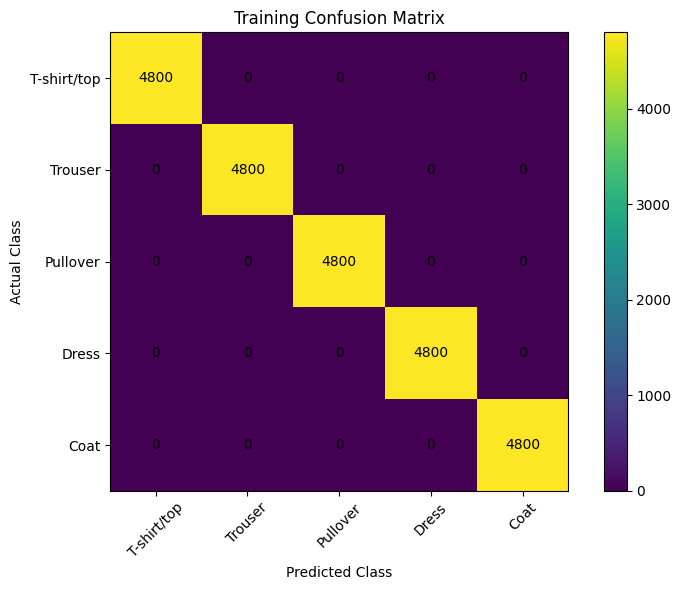

In [38]:
# ==========================================
# PART 34: PLOT TRAINING CONFUSION MATRIX
# ==========================================

plt.figure(

    figsize=(8, 6)

)


plt.imshow(
    training_cm
)


plt.colorbar()


plt.xlabel(
    "Predicted Class"
)


plt.ylabel(
    "Actual Class"
)


plt.title(
    "Training Confusion Matrix"
)


plt.xticks(

    range(5),

    class_names,

    rotation=45

)


plt.yticks(

    range(5),

    class_names

)


for i in range(5):


    for j in range(5):


        plt.text(

            j,

            i,

            training_cm[i, j],

            ha="center",

            va="center"

        )


plt.tight_layout()


plt.show()

In [39]:
# ==========================================
# PART 35: FINAL SUMMARY
# ==========================================

print(
    "\n"
    + "=" * 60
)


print(
    "FINAL RESULTS"
)


print(
    "=" * 60
)


print(
    f"Best Architecture: "
    f"{best_architecture}"
)


print(
    f"Best Optimizer: "
    f"{best_optimizer}"
)


print(
    f"Training Accuracy: "

    f"{best_result['Training Accuracy']:.2f}%"
)


print(
    f"Validation Accuracy: "

    f"{best_result['Validation Accuracy']:.2f}%"
)


print(
    f"Test Accuracy: "

    f"{test_accuracy * 100:.2f}%"
)


print(
    f"Epochs to Convergence: "

    f"{best_result['Epochs to Convergence']}"
)


FINAL RESULTS
Best Architecture: Architecture_2
Best Optimizer: Adam
Training Accuracy: 100.00%
Validation Accuracy: 92.05%
Test Accuracy: 92.36%
Epochs to Convergence: 244
